# 10. Final Model Comparison
Guideline section **V** (compare algorithms, before/after hyper-parameter optimisation, best performing algorithm).
We collect the default and tuned test results of all six algorithms from notebooks 03-08 and evaluate the saved models on the same 20% test set (23,842 bookings).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
import joblib
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, brier_score_loss

results_dir = '../results/10_model_comparison' if os.path.exists('../results') else 'results/10_model_comparison'
models_dir = '../models' if os.path.exists('../models') else 'models'
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
base_results = '../results' if os.path.exists('../results') else 'results'
os.makedirs(results_dir, exist_ok=True)

X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()
model_folders = {'KNN': ('03_knn', 'knn'), 'Decision Tree': ('04_decision_tree', 'decision_tree'),
                 'Random Forest': ('05_random_forest', 'random_forest'), 'XGBoost': ('06_xgboost', 'xgboost'),
                 'LightGBM': ('07_lightgbm', 'lightgbm'), 'MLP Neural Net': ('08_mlp', 'mlp')}

## 1. Before vs after hyper-parameter optimisation (all six models)

Accuracy         F1-Score         ROC-AUC        
Variant         Default   Tuned  Default   Tuned Default   Tuned
Model                                                           
Decision Tree    0.8652  0.8671   0.8198  0.8151  0.8597  0.9387
KNN              0.8361  0.8603   0.7738  0.8046  0.8998  0.9309
LightGBM         0.8781  0.8937   0.8306  0.8539  0.9516  0.9623
MLP Neural Net   0.8712  0.8701   0.8178  0.8206  0.9443  0.9447
Random Forest    0.8920  0.8938   0.8472  0.8499  0.9590  0.9594
XGBoost          0.8812  0.8811   0.8352  0.8353  0.9539  0.9542

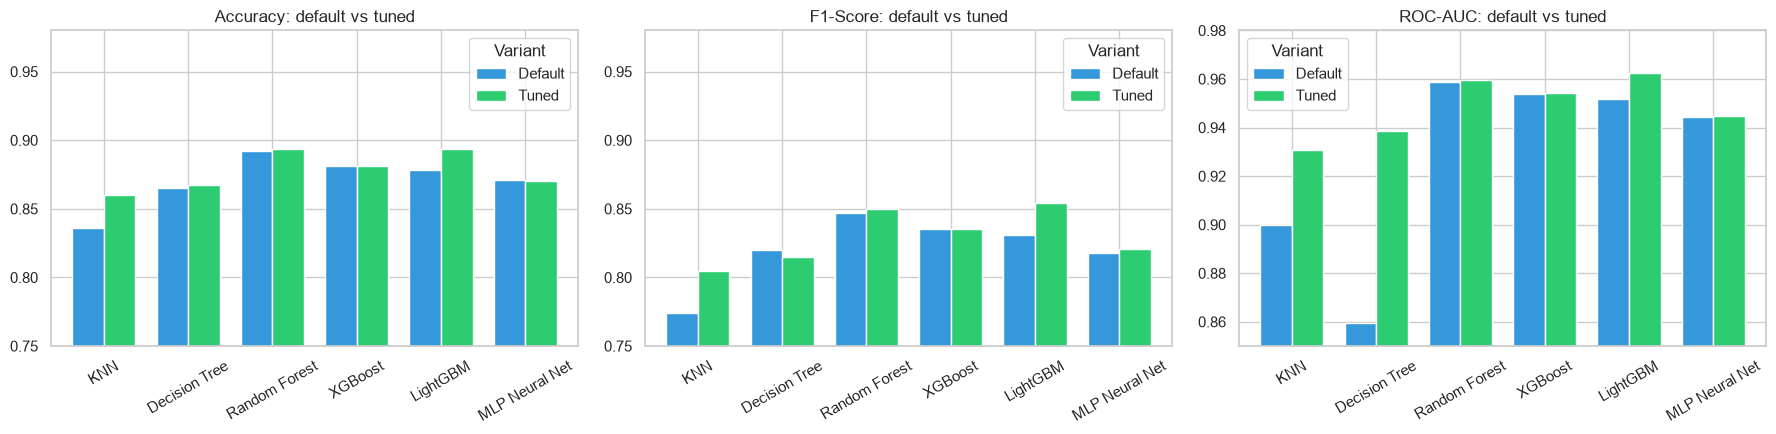

In [2]:
rows = []
for model_name, (folder, _) in model_folders.items():
    m = pd.read_csv(f'{base_results}/{folder}/metrics_comparison.csv').set_index('Metric')
    for variant, col in [('Default', 'Default (No Tuning)'), ('Tuned', 'Tuned')]:
        rows.append({'Model': model_name, 'Variant': variant, **m[col].to_dict()})
both = pd.DataFrame(rows)
both.to_csv(f'{results_dir}/default_vs_tuned_all_models.csv', index=False)
display(both.pivot(index='Model', columns='Variant', values=['Accuracy', 'F1-Score', 'ROC-AUC']).round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ['Accuracy', 'F1-Score', 'ROC-AUC']):
    pv = both.pivot(index='Model', columns='Variant', values=metric).loc[list(model_folders)]
    pv.plot(kind='bar', ax=ax, color=['#3498db', '#2ecc71'], width=.75)
    ax.set_ylim(0.75 if metric != 'ROC-AUC' else 0.85, 0.98)
    ax.set_title(f'{metric}: default vs tuned')
    ax.tick_params(axis='x', rotation=30)
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig(f'{results_dir}/default_vs_tuned_all_models.png', dpi=300)
plt.show()

## 2. Master leaderboard of the tuned models

In [3]:
leaderboard_df = both[both.Variant == 'Tuned'].drop(columns='Variant')
probs = {}
for model_name, (_, key) in model_folders.items():
    probs[model_name] = joblib.load(f'{models_dir}/{key}_tuned.joblib').predict_proba(X_test)[:, 1]
leaderboard_df['PR-AUC (AP)'] = leaderboard_df['Model'].map(lambda n: average_precision_score(y_test, probs[n]))
leaderboard_df['Brier score'] = leaderboard_df['Model'].map(lambda n: brier_score_loss(y_test, probs[n]))
leaderboard_df = leaderboard_df.sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
leaderboard_df.index = leaderboard_df.index + 1
leaderboard_df.to_csv(f'{results_dir}/master_model_leaderboard.csv', index_label='Rank')
print('=== MASTER MODEL LEADERBOARD (tuned models, test set) ===')
leaderboard_df.round(4)

=== MASTER MODEL LEADERBOARD (tuned models, test set) ===


,Model,Accuracy,ROC-AUC,F1-Score,Precision,Recall,Specificity,PR-AUC (AP),Brier score
1,LightGBM,0.8937,0.9623,0.8539,0.8701,0.8383,0.9263,0.9435,0.0749
2,Random Forest,0.8938,0.9594,0.8499,0.8934,0.8104,0.9430,0.9422,0.0765
3,XGBoost,0.8811,0.9542,0.8353,0.8585,0.8133,0.9210,0.9319,0.0831
4,MLP Neural Net,0.8701,0.9447,0.8206,0.8407,0.8015,0.9105,0.9207,0.0908
5,Decision Tree,0.8671,0.9387,0.8151,0.8419,0.7900,0.9125,0.9089,0.0928
6,KNN,0.8603,0.9309,0.8046,0.8355,0.7759,0.9100,0.9065,0.0979


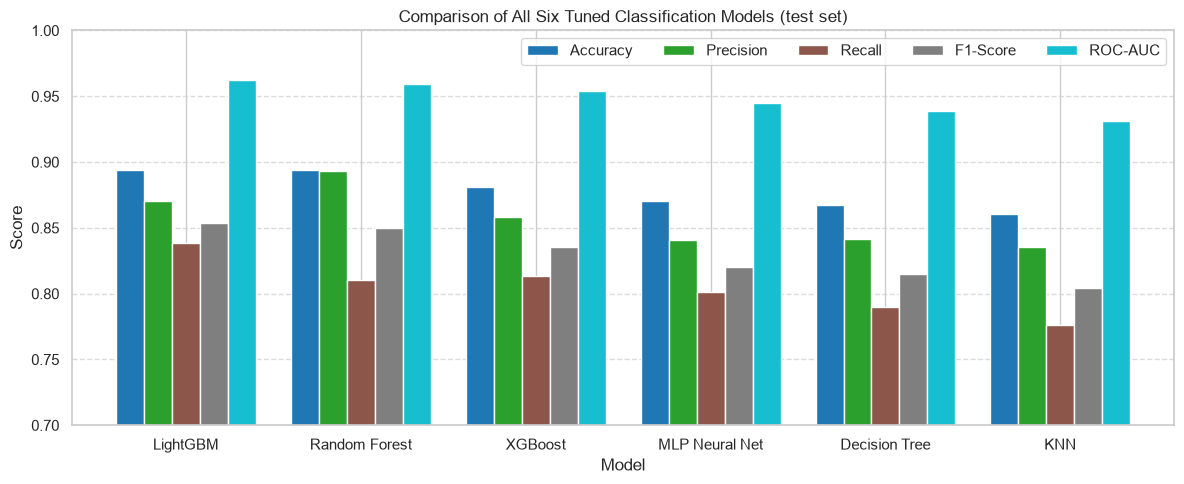

In [4]:
plt.figure(figsize=(12, 5))
lb = leaderboard_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']]
lb.plot(kind='bar', width=.8, ax=plt.gca(), colormap='tab10')
plt.ylim(0.7, 1.0)
plt.title('Comparison of All Six Tuned Classification Models (test set)')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='upper right', ncol=5)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(f'{results_dir}/model_leaderboard_barchart.png', dpi=300)
plt.show()

## 3. ROC and Precision-Recall curves of all six tuned models

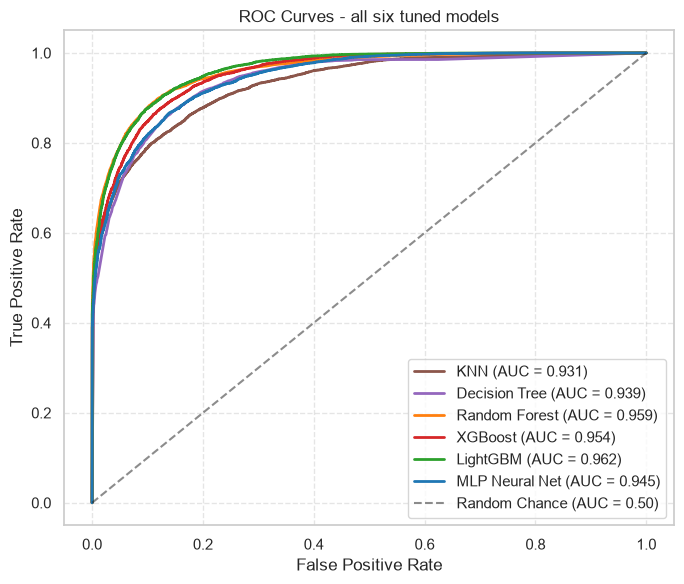

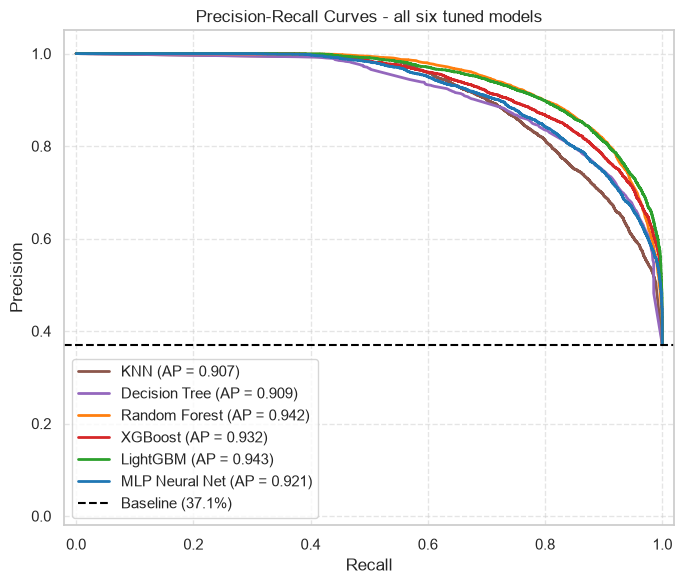

In [5]:
colors = dict(zip(model_folders, ['#8c564b', '#9467bd', '#ff7f0e', '#d62728', '#2ca02c', '#1f77b4']))
plt.figure(figsize=(7, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc(fpr, tpr):.3f})', lw=2, color=colors[name])
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.50)')
plt.title('ROC Curves - all six tuned models')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(loc='lower right'); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.savefig(f'{results_dir}/combined_roc_curves.png', dpi=300); plt.show()

plt.figure(figsize=(7, 6))
for name, p in probs.items():
    pc, rc, _ = precision_recall_curve(y_test, p)
    plt.plot(rc, pc, label=f'{name} (AP = {average_precision_score(y_test, p):.3f})', lw=2, color=colors[name])
plt.axhline(y_test.mean(), color='black', linestyle='--', label=f'Baseline ({y_test.mean()*100:.1f}%)')
plt.title('Precision-Recall Curves - all six tuned models')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.xlim([-0.02, 1.02]); plt.ylim([-0.02, 1.05])
plt.legend(loc='lower left'); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.savefig(f'{results_dir}/combined_pr_curves.png', dpi=300); plt.show()

## 4. Confusion matrices of all six tuned models

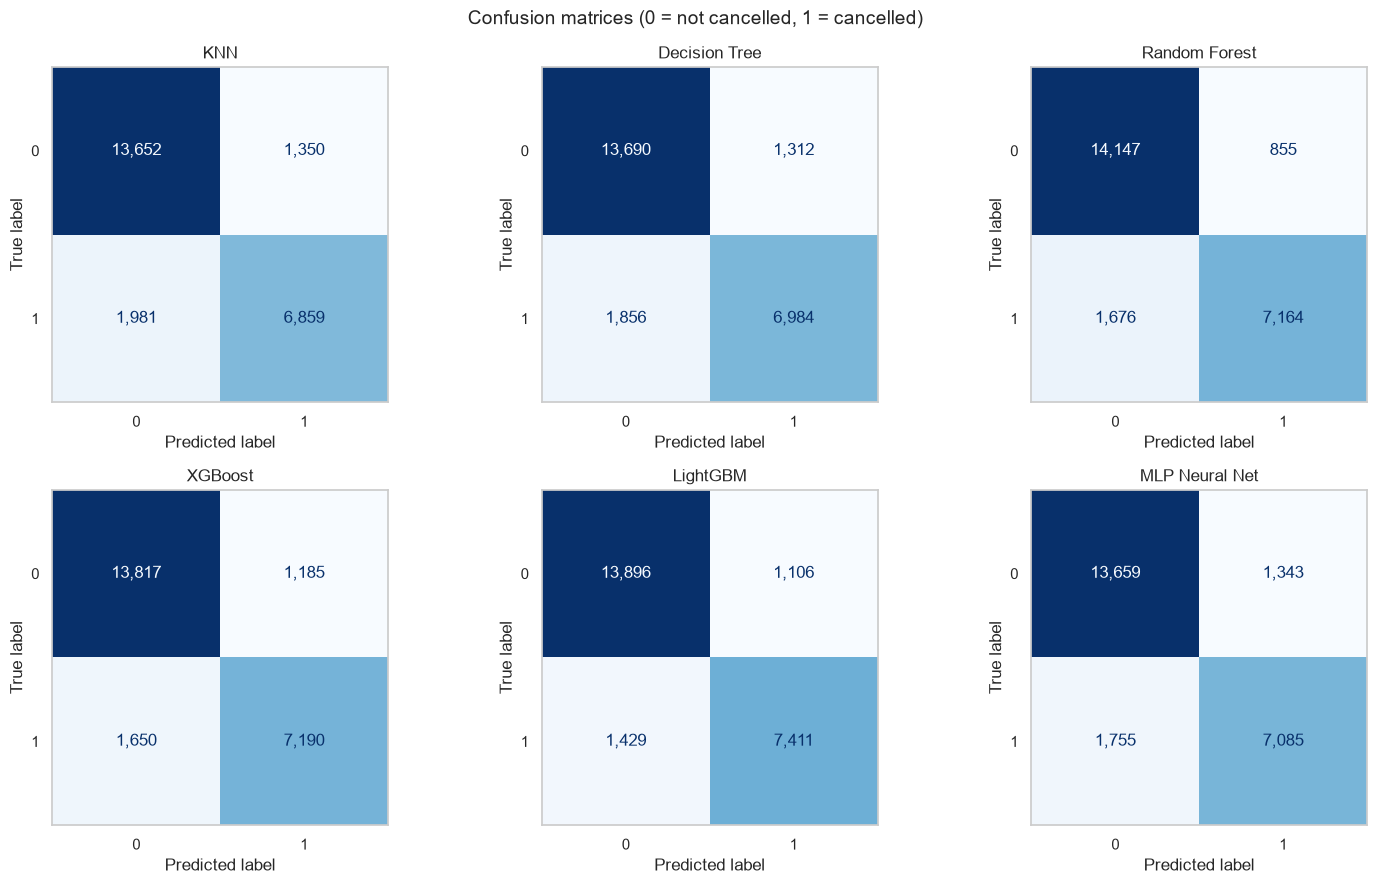

,Model,TN,FP,FN,TP
0,KNN,13652,1350,1981,6859
1,Decision Tree,13690,1312,1856,6984
2,Random Forest,14147,855,1676,7164
3,XGBoost,13817,1185,1650,7190
4,LightGBM,13896,1106,1429,7411
5,MLP Neural Net,13659,1343,1755,7085


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
cm_rows = []
for ax, (name, p) in zip(axes.ravel(), probs.items()):
    pred = (p >= .5).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap='Blues', colorbar=False, values_format=',')
    ax.set_title(name); ax.grid(False)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    cm_rows.append({'Model': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
plt.suptitle('Confusion matrices (0 = not cancelled, 1 = cancelled)', fontsize=14)
plt.tight_layout(); plt.savefig(f'{results_dir}/confusion_matrices_all.png', dpi=300); plt.show()
pd.DataFrame(cm_rows).to_csv(f'{results_dir}/confusion_matrices_all.csv', index=False)
pd.DataFrame(cm_rows)

## 5. What drives the best model? (LightGBM feature importance, gain)

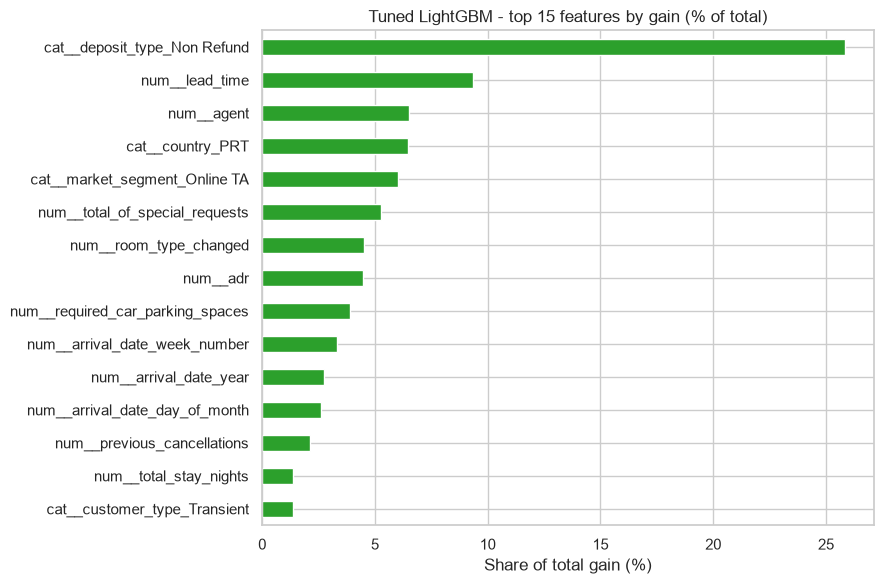

cat__deposit_type_Non Refund        25.84
num__lead_time                       9.34
num__agent                           6.52
cat__country_PRT                     6.48
cat__market_segment_Online TA        6.04
num__total_of_special_requests       5.26
num__room_type_changed               4.51
num__adr                             4.45
num__required_car_parking_spaces     3.90
num__arrival_date_week_number        3.33
num__arrival_date_year               2.75
num__arrival_date_day_of_month       2.62
num__previous_cancellations          2.13
num__total_stay_nights               1.38
cat__customer_type_Transient         1.35
dtype: float64

In [7]:
best = joblib.load(f'{models_dir}/lightgbm_tuned.joblib')
gain = pd.Series(best.booster_.feature_importance(importance_type='gain'), index=X_test.columns)
gain = (gain / gain.sum() * 100).sort_values(ascending=False)
gain.round(3).to_csv(f'{results_dir}/best_model_feature_importance_gain.csv', header=['gain_%'])
plt.figure(figsize=(9, 6))
gain.head(15)[::-1].plot(kind='barh', color='#2ca02c')
plt.title('Tuned LightGBM - top 15 features by gain (% of total)')
plt.xlabel('Share of total gain (%)')
plt.tight_layout(); plt.savefig(f'{results_dir}/best_model_feature_importance.png', dpi=300); plt.show()
gain.head(15).round(2)

## Conclusion
* **Best model: tuned LightGBM** - accuracy 89.37%, F1 0.8539, ROC-AUC 0.9623, PR-AUC 0.9435, recall 83.83% and the lowest Brier score (0.0749, best calibrated probabilities).
* **Random Forest** is practically tied in accuracy (89.38%) and has the highest precision (89.34%) and specificity (94.30%), i.e. the fewest false alarms (855) - useful if the predictions are used for overbooking - but it misses 247 more cancellations than LightGBM.
* Ranking by F1: LightGBM > Random Forest > XGBoost > MLP > Decision Tree > KNN. Tree ensembles win because cancellations depend on non-linear rules and interactions of categorical features.
* Hyper-parameter tuning improved the ROC-AUC of all six models; the largest gains were for the Decision Tree (+0.079 ROC-AUC, pruning stops overfitting), KNN (+0.031 F1) and LightGBM (+0.023 F1).
* Most important drivers of the best model: Non Refund deposit, lead time, agent, country = PRT, Online TA segment, special requests.
* **Practical use:** flag high-risk bookings (long lead time, non-refundable group blocks, no special requests) and overbook selectively / contact these guests early.